# Ensemble Methods, Part 1: Bagging and Random Forests

Companion notebook for the article on Medium by Roberto Jhoshua Alegre Ventura.

The notebook follows the order of the article and reproduces every number and chart in it. The figures are saved in `figures/`. All datasets are synthetic, so it runs offline in a few minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import BaggingClassifier, BaggingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from plot_style import BLUE, FRAME, GOLD, INK, LIGHT, RED, SHADE, TEAL, apply_style, new_figure, save

apply_style()

## When does averaging help?

Each simulated person makes an error of about 55 lb. In the second crowd, a fraction ρ of that error is shared by everyone, which makes the errors of any two people correlated. For each crowd size we simulate 3,000 crowds and measure the typical error of their average.

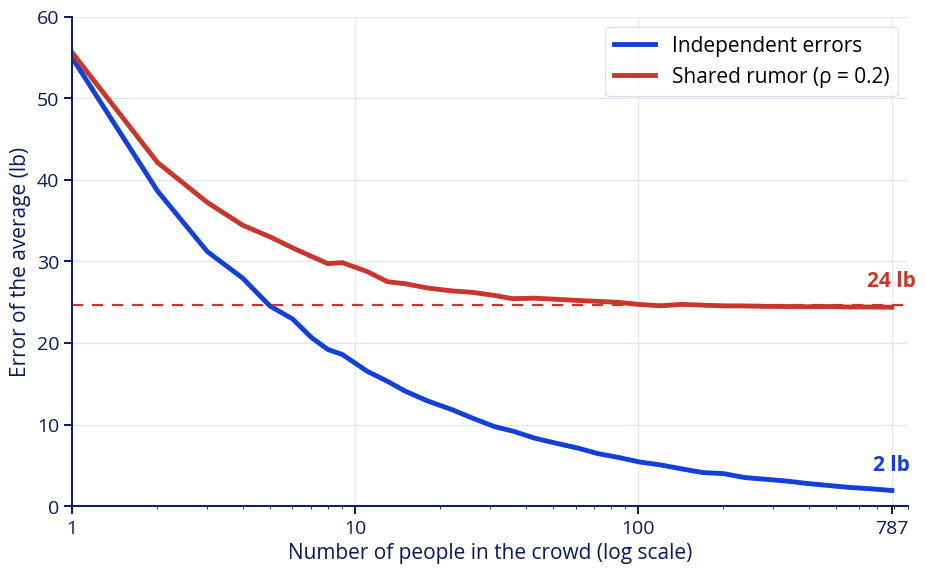

Error with 787 independent people: 1.9 lb
Error with 787 people and a shared rumor: 24.4 lb


In [2]:
rng = np.random.default_rng(7)
sigma = 55
n_crowds = 3000
crowd_sizes = np.unique(np.round(np.logspace(0, np.log10(787), 40)).astype(int))

fig, ax = new_figure(430)
final_error = {}
for rho, color, label in [(0.0, BLUE, "Independent errors"), (0.2, RED, "Shared rumor (ρ = 0.2)")]:
    # One shared error per crowd, plus an independent error per person
    shared = rng.normal(0, sigma, n_crowds)
    rmse = []
    for n in crowd_sizes:
        errors = np.sqrt(rho) * shared[:, None] + np.sqrt(1 - rho) * rng.normal(0, sigma, (n_crowds, n))
        rmse.append(np.sqrt(np.mean(errors.mean(axis=1) ** 2)))
    ax.plot(crowd_sizes, rmse, color=color, label=label)
    final_error[rho] = rmse[-1]

# With correlation rho, the error can never go below sqrt(rho) * sigma
ax.axhline(np.sqrt(0.2) * sigma, color=RED, lw=1.6, ls=(0, (5, 4)))
ax.text(787, final_error[0.2] + 2.5, f"{final_error[0.2]:.0f} lb", color=RED, fontsize=15, weight="bold", ha="center")
ax.text(787, final_error[0.0] + 2.5, f"{final_error[0.0]:.0f} lb", color=BLUE, fontsize=15, weight="bold", ha="center")
ax.legend(loc="upper right", fontsize=15, frameon=True, facecolor="white", edgecolor=FRAME)
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 787], ["1", "10", "100", "787"])
ax.set_xlabel("Number of people in the crowd (log scale)")
ax.set_ylabel("Error of the average (lb)")
ax.set_ylim(0, 60)
ax.set_xlim(1, 900)
fig.subplots_adjust(left=0.11, right=0.97, bottom=0.15, top=0.97)
save(fig, "figures/fig02_crowd_error.png")
plt.show()

print(f"Error with 787 independent people: {final_error[0.0]:.1f} lb")
print(f"Error with 787 people and a shared rumor: {final_error[0.2]:.1f} lb")

## Bootstrap sampling

The same sample shown in the article.

In [3]:
rng = np.random.default_rng(11)
rows = np.array(list("ABCDEFGH"))

sample = rng.choice(rows, size=len(rows), replace=True)
left_out = np.setdiff1d(rows, sample)

print("Bootstrap sample:", "".join(sample))
print("Out-of-bag rows: ", "".join(left_out))

Bootstrap sample: BBGDEEFA
Out-of-bag rows:  CH


## Why about a third of the rows are left out

We draw 5,000 bootstrap samples from 1,000 rows and record the fraction of rows that never appear.

In [4]:
rng = np.random.default_rng(1)
n_rows = 1000
fractions = np.array([1 - len(np.unique(rng.integers(0, n_rows, n_rows))) / n_rows for _ in range(5000)])

print(f"Theoretical limit 1/e: {np.exp(-1):.3f}")
print(f"Mean fraction left out: {fractions.mean():.3f}")
print(f"Range: {fractions.min():.3f} to {fractions.max():.3f}")

Theoretical limit 1/e: 0.368
Mean fraction left out: 0.368
Range: 0.335 to 0.404


## Out-of-bag error

Four bootstrap samples over 8 rows. Each cell counts how many times a row was drawn for a tree, and a zero means the row is out-of-bag for that tree. This is the matrix shown in the article.

In [5]:
rng = np.random.default_rng(11)
n_rows, n_trees = 8, 4
counts = np.zeros((n_trees, n_rows), dtype=int)
for tree in range(n_trees):
    indices = rng.integers(0, n_rows, n_rows)
    np.add.at(counts[tree], indices, 1)

matrix = pd.DataFrame(counts, index=[f"Tree {t + 1}" for t in range(n_trees)], columns=list("ABCDEFGH"))
print(matrix.replace(0, "OOB"))

          A  B    C    D    E    F    G    H
Tree 1    1  2  OOB    1    2    1    1  OOB
Tree 2    1  2  OOB    2    2  OOB  OOB    1
Tree 3  OOB  1    1  OOB    2  OOB    2    2
Tree 4  OOB  1    2    1  OOB    1    2    1


## Which models benefit from bagging?

Each model is evaluated on its own and inside a `BaggingClassifier` with 50 copies, using 5-fold cross-validation on the 1,500-row dataset.

In [6]:
data = pd.read_csv("data/classification_1500.csv")
X, y = data.drop(columns="y"), data["y"]
cv = StratifiedKFold(5, shuffle=True, random_state=0)

base_models = {
    "Deep decision tree": DecisionTreeClassifier(random_state=0),
    "Small neural network": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=[64], max_iter=600, random_state=0)),
    "k-NN (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "k-NN (k = 1)": make_pipeline(StandardScaler(), KNeighborsClassifier(1)),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC())
}

results = []
for name, model in base_models.items():
    alone = cross_val_score(model, X, y, cv=cv).mean()
    bagged_model = BaggingClassifier(model, n_estimators=50, random_state=0, n_jobs=-1)
    bagged = cross_val_score(bagged_model, X, y, cv=cv).mean()
    results.append((name, alone, bagged))
    print(f"{name:22s} alone {alone:.3f}  bagged {bagged:.3f}  ({(bagged - alone) * 100:+.1f} pts)")

Deep decision tree     alone 0.788  bagged 0.871  (+8.3 pts)


Small neural network   alone 0.879  bagged 0.887  (+0.7 pts)


k-NN (k = 15)          alone 0.838  bagged 0.844  (+0.6 pts)


k-NN (k = 1)           alone 0.781  bagged 0.783  (+0.3 pts)


Logistic regression    alone 0.755  bagged 0.756  (+0.1 pts)


SVM (RBF kernel)       alone 0.865  bagged 0.861  (-0.5 pts)


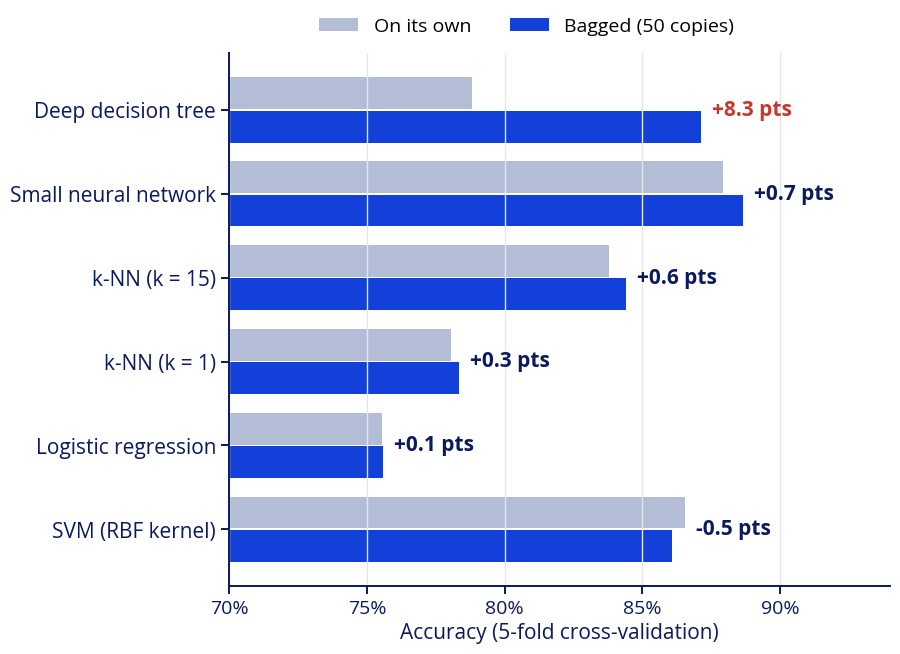

In [7]:
fig, ax = new_figure(480)
positions = np.arange(len(results))[::-1]
for pos, (name, alone, bagged) in zip(positions, results):
    ax.barh(pos + 0.2, alone, height=0.38, color=LIGHT, label="On its own" if pos == positions[0] else None)
    ax.barh(pos - 0.2, bagged, height=0.38, color=BLUE, label="Bagged (50 copies)" if pos == positions[0] else None)
    diff = (bagged - alone) * 100
    # Highlight the only model with a large gain
    ax.text(max(alone, bagged) + 0.004, pos, f"{diff:+.1f} pts", va="center", fontsize=15, weight="bold", color=RED if diff > 2 else INK)

ax.set_yticks(positions, [r[0] for r in results], fontsize=15)
ax.set_xlim(0.70, 0.94)
ax.set_xticks([0.70, 0.75, 0.80, 0.85, 0.90], ["70%", "75%", "80%", "85%", "90%"])
ax.set_xlabel("Accuracy (5-fold cross-validation)")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
fig.subplots_adjust(left=0.30, right=0.98, bottom=0.12, top=0.92)
save(fig, "figures/fig07_base_models.png")
plt.show()

### How unstable is a deep tree?

We train the same model 40 times, each time on a new sample of 60 noisy points from the same curve. The blue band covers the middle 80% of the 40 predictions at each point.

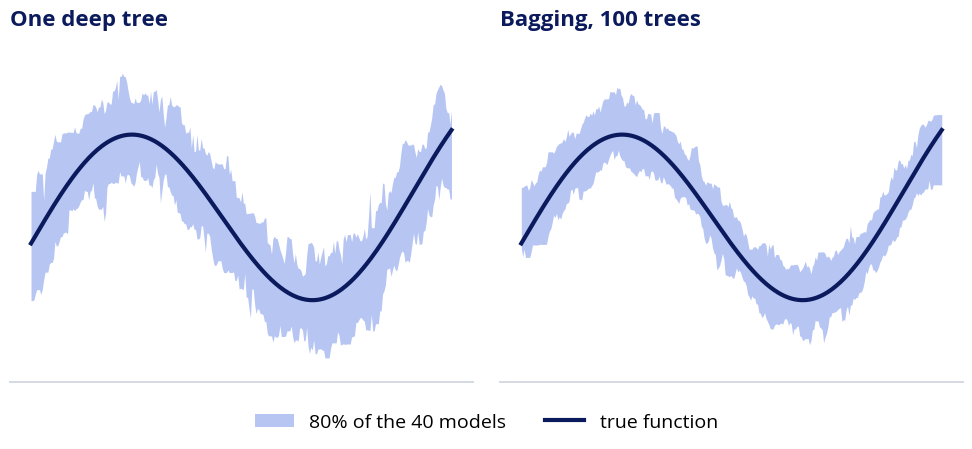

The band is 31% narrower with bagging


In [8]:
rng = np.random.default_rng(10)
true_function = lambda x: np.sin(2.2 * np.pi * x) + 0.6 * x
x_grid = np.linspace(0, 1, 300)[:, None]

fig, axes = new_figure(330, ncols=2, sharey=True)
band_width = {}
for ax, kind in zip(axes, ["tree", "bagging"]):
    predictions = []
    for seed in range(40):
        x = rng.uniform(0, 1, 60)[:, None]
        y_noisy = true_function(x[:, 0]) + rng.normal(0, 0.4, 60)
        if kind == "tree":
            model = DecisionTreeRegressor(random_state=seed)
        else:
            model = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=seed)
        predictions.append(model.fit(x, y_noisy).predict(x_grid))
    predictions = np.array(predictions)
    low, high = np.percentile(predictions, 10, axis=0), np.percentile(predictions, 90, axis=0)
    band_width[kind] = np.mean(high - low)

    ax.fill_between(x_grid[:, 0], low, high, color=BLUE, alpha=0.30, lw=0, label="80% of the 40 models")
    ax.plot(x_grid[:, 0], true_function(x_grid[:, 0]), color=INK, lw=3, label="true function")
    ax.set_xticks([])
    ax.grid(False)
    ax.tick_params(labelleft=False, left=False)
    ax.set_ylim(-1.45, 2.2)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(FRAME)

axes[0].set_title("One deep tree", loc="left")
axes[1].set_title("Bagging, 100 trees", loc="left")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.03, -0.04), ncol=2)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.14, top=0.9, wspace=0.06)
save(fig, "figures/fig08_variance_band.png")
plt.show()

print(f"The band is {1 - band_width['bagging'] / band_width['tree']:.0%} narrower with bagging")

## Random forests

A single tree, bagging and a random forest, trained on the same 260 points and evaluated on 4,000 new points.

One tree       test accuracy: 0.862


Bagging        test accuracy: 0.896


Random forest  test accuracy: 0.893


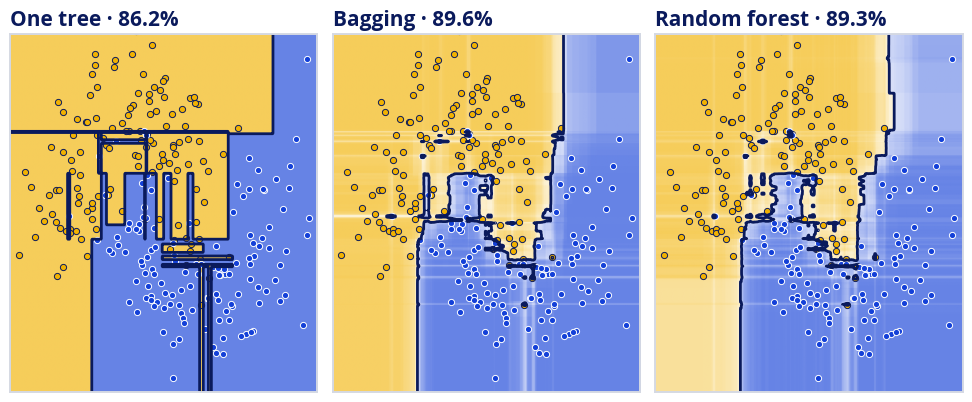

In [9]:
train = pd.read_csv("data/moons_train.csv")
test = pd.read_csv("data/moons_test.csv")
X_tr, y_tr = train[["x1", "x2"]].to_numpy(), train["y"].to_numpy()
X_te, y_te = test[["x1", "x2"]].to_numpy(), test["y"].to_numpy()

models = [
    ("One tree", DecisionTreeClassifier(random_state=0)),
    ("Bagging", BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=0)),
    ("Random forest", RandomForestClassifier(n_estimators=200, max_features=1, random_state=0))
]

fig, axes = new_figure(300, ncols=3)
xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 420), np.linspace(-1.2, 1.7, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]
for ax, (title, model) in zip(axes, models):
    model.fit(X_tr, y_tr)
    accuracy = model.score(X_te, y_te)
    proba = model.predict_proba(grid_points)[:, 1].reshape(xx.shape)

    # Color each region by its predicted class, lighter where the trees disagree
    confidence = np.clip(np.abs(proba - 0.5) * 2, 0, 1)
    rgb = np.where(proba[..., None] > 0.5, np.array([19, 64, 216]) / 255, np.array([242, 178, 0]) / 255)
    image = np.concatenate([rgb, (0.15 + 0.5 * confidence)[..., None]], axis=2)
    ax.imshow(image, extent=(xx.min(), xx.max(), yy.min(), yy.max()), origin="lower", interpolation="bilinear", aspect="auto")
    ax.contour(xx, yy, proba, levels=[0.5], colors=INK, linewidths=2)
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], s=20, c=GOLD, edgecolors=INK, linewidths=0.7)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], s=20, c=BLUE, edgecolors="white", linewidths=0.7)

    ax.set_title(f"{title} · {accuracy:.1%}", loc="left", fontsize=15)
    ax.set_xlim(-1.6, 2.6)
    ax.set_ylim(-1.2, 1.7)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(FRAME)
    print(f"{title:14s} test accuracy: {accuracy:.3f}")

fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.88, wspace=0.05)
save(fig, "figures/fig10_boundaries.png")
plt.show()

## How many trees?

Forests of increasing size on the 1,500-row dataset. `warm_start=True` adds trees to the existing forest instead of training a new one each time. Each curve is the average over five random seeds.

/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


max_features=sqrt  OOB error with 300 trees: 0.119


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


max_features=log2  OOB error with 300 trees: 0.122


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


max_features=None  OOB error with 300 trees: 0.111


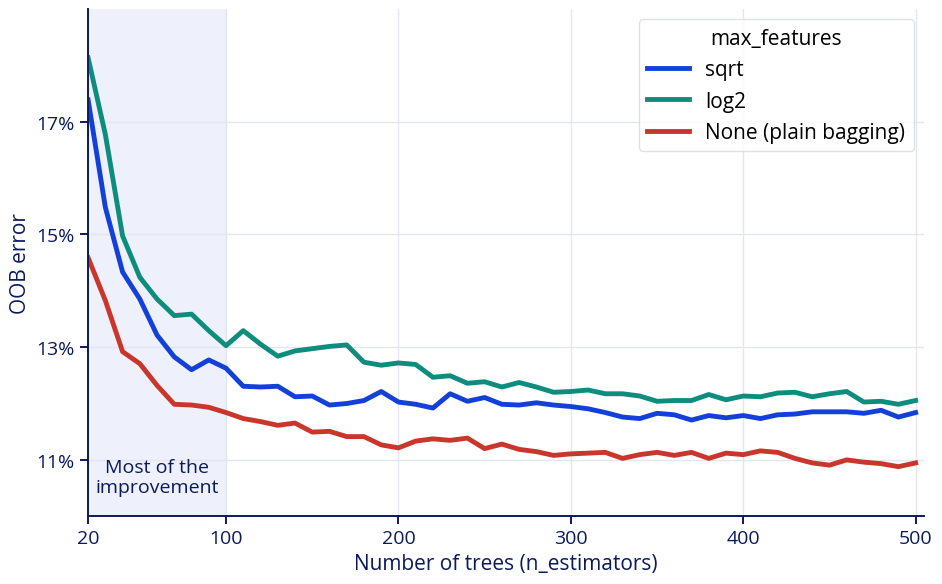

In [10]:
n_trees = list(range(20, 501, 10))
settings = [("sqrt", "sqrt", BLUE), ("log2", "log2", TEAL), (None, "None (plain bagging)", RED)]

fig, ax = new_figure(440)
ax.axvspan(20, 100, color=SHADE, lw=0)
for max_features, label, color in settings:
    oob_error = np.zeros(len(n_trees))
    for seed in range(5):
        forest = RandomForestClassifier(warm_start=True, oob_score=True, max_features=max_features, random_state=seed, n_jobs=-1)
        for k, n in enumerate(n_trees):
            forest.set_params(n_estimators=n)
            forest.fit(X, y)
            oob_error[k] += (1 - forest.oob_score_) / 5
    ax.plot(n_trees, oob_error, color=color, label=label)
    print(f"max_features={str(max_features):5s} OOB error with 300 trees: {oob_error[n_trees.index(300)]:.3f}")

ax.text(60, 0.1035, "Most of the\nimprovement", ha="center", va="bottom", fontsize=14, color=INK)
ax.set_ylim(0.10, 0.19)
ax.set_xlim(20, 505)
ax.set_xticks([20, 100, 200, 300, 400, 500])
ax.legend(title="max_features", loc="upper right", fontsize=15, title_fontsize=15, frameon=True, facecolor="white", edgecolor=FRAME)
ax.set_yticks([0.11, 0.13, 0.15, 0.17], ["11%", "13%", "15%", "17%"])
ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("OOB error")
fig.subplots_adjust(left=0.11, right=0.97, bottom=0.14, top=0.97)
save(fig, "figures/fig11_oob_curve.png")
plt.show()

## Try it yourself

The final example from the article. It generates the same 1,500-row dataset and holds out a test set to check the OOB estimate.

In [11]:
# Generate synthetic classification data
X, y = make_classification(
    n_samples=1500,
    n_features=25,
    n_informative=8,
    n_redundant=4,
    flip_y=0.03,
    random_state=42)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0)

# Train a Random Forest with OOB evaluation
forest = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",  # Features considered at each split
    oob_score=True,       # Estimate accuracy using out-of-bag rows
    n_jobs=-1,
    random_state=42)
forest.fit(X_train, y_train)

print(f"OOB accuracy: {forest.oob_score_:.3f}")
print(f"Test accuracy: {forest.score(X_test, y_test):.3f}")

OOB accuracy: 0.868
Test accuracy: 0.877
